# MyFinSight 분석 결과 한눈에 보기

`output/13_results.json` 하나만 읽어서, 파이프라인이 **무엇을 받아(요청) → 어떻게 이해하고(의도) → 어떤 종목을 골라(선정) → 어떻게 나누고(구성) → 과거에 적용하면 어땠고(백테스트) → 기준을 통과했는지(검증)** 를 순서대로 보여줍니다.
각 절의 표와 그래프는 모두 같은 결과 파일의 숫자입니다.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "AppleGothic"      # macOS 한글 폰트 (다른 OS: 'Malgun Gothic' / 'NanumGothic')
mpl.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

import os
RESULTS = Path(os.environ.get("MYFINSIGHT_RESULTS", "../output/13_results.json"))   # 기본: notebooks/ 기준 상대 경로
R = json.loads(RESULTS.read_text(encoding="utf-8"))
pct = lambda x: "–" if x is None else f"{x*100:+.2f}%"
pct1 = lambda x: "–" if x is None else f"{x*100:.1f}%"
usd = lambda x: "–" if x is None else f"{x:,.2f} USD"
krw = lambda x: "–" if x is None else f"{x:,.0f}원"
print("request_id:", R["request_id"], "| generated:", R["generated_at"], "| pipeline:", R["pipeline_version"])

request_id: req_2026-10-10_trv1 | generated: 2026-10-10T12:06:04 | pipeline: mockup-2026.10


## 1. 요청 — 사용자가 입력한 것

In [2]:
q, d, c, h, r = R["request"], R["request"]["derived"], R["request"]["capital"], R["request"]["horizon"], R["request"]["risk"]
rows = [("투자금", f"{c['initial_amount']:,.0f}원 → {usd(d['initial_amount_usd'])}  (환율 {R['money_krw']['direction']}, {d['fx_date']})"),
        ("월 적립", f"{c['monthly_contribution']:,.0f}원 (매월 {c['contribution_day']}일) → {usd(d['monthly_contribution_usd'])}"),
        ("투자기간", f"{h['target_years']}년, 시작 희망일 {h['start_date']}"),
        ("투자성향", f"{r['risk_tolerance']} · 손실 감내 수준 {r['max_drawdown_tolerance']:.0%} · 손실 시 {r['loss_reaction']}"),
        ("목표 수익률 / 비교지수", f"연 {r['target_annual_return']:.0%} / {r['benchmark']}"),
        ("전략 템플릿 / 기준 비중", f"{q['strategy_preference']['template']} / {q['strategy_preference']['baseline_weighting']}"),
        ("투자 아이디어", q["natural_language"]["idea"])]
pd.DataFrame(rows, columns=["항목", "내용"]).set_index("항목")

,내용
항목,
투자금,"30,000,000원 → 22,387.73 USD (환율 1 USD = 1,340.02 KRW, 2026-10-09)"
월 적립,"500,000원 (매월 25일) → 373.13 USD"
투자기간,"3.0년, 시작 희망일 2026-10-09"
투자성향,moderate · 손실 감내 수준 30% · 손실 시 hold
목표 수익률 / 비교지수,연 10% / SPY
전략 템플릿 / 기준 비중,momentum / inverse_volatility
투자 아이디어,"코로나 이후 여행과 외식 소비가 계속 늘고 있다고 생각해요. 항공사, 호텔·리조트, 크루즈, 외식 프랜차이즈, 테마파크·레저 같은 미국 ..."


## 2. 의도 해석 — 분석 모델이 아이디어를 어떻게 이해했나

In [3]:
I = R["intent"]
print(I["interpretation"]["summary_ko"]); print()
themes = pd.DataFrame([{"테마": t["label_ko"], "설명": t["description_ko"], "GICS 코드": ", ".join(t["gics_codes"]), "키워드": ", ".join(t["keywords"][:6])} for t in I["interpretation"]["themes"]])
display(themes.set_index("테마"))
cons = q["constraints"]
display(pd.DataFrame([("종목 수", f"목표 {cons['num_holdings']['target']} (허용 {cons['num_holdings']['min']}~{cons['num_holdings']['max']})"), ("종목당 상한", f"{cons['max_weight_per_stock']:.0%}"), ("섹터당 상한", f"{cons['max_weight_per_sector']:.0%}"),
                      ("리밸런싱", d["rebalance_rule"]["description_ko"]), ("제외 테마", ", ".join(cons["exclude_themes"]) or "없음"),
                      ("변동성 선호 / 허용 MDD", f"{I['risk_params']['volatility_preference']} / {I['risk_params']['effective_max_drawdown']:.0%}"), ("해석 메모", I["risk_params"]["notes_ko"])], columns=["항목", "값"]).set_index("항목"))
if I["interpretation"]["conflicts"]:
    display(pd.DataFrame(I["interpretation"]["conflicts"]).rename(columns={"field": "항목", "issue_ko": "확인한 점", "resolution_ko": "처리"}))

여행·외식 소비 회복의 수혜를 기대하며 항공사, 호텔·리조트·크루즈, 외식 프랜차이즈, 테마파크·레저 기업에 분산 투자하려는 의도입니다. 최근 1년 수익률을 기준으로 12개 안팎의 종목을 선정하고, 카지노·도박 및 담배 관련 기업은 제외합니다.



,설명,GICS 코드,키워드
테마,,,
항공사,승객을 대상으로 국내외 항공 운송 서비스를 제공하고 여객 항공 노선을 운영하는 기업입니다.,20302010,"passenger airline, air carrier, airline, air travel, commercial aviation, pa..."
호텔·리조트·크루즈,"호텔과 리조트 숙박, 휴양 시설 또는 유람선 여행 서비스를 제공하는 기업입니다.",25301020,"hotel, resort, lodging, hospitality, cruise line, cruise ship"
외식·레스토랑 프랜차이즈,매장이나 프랜차이즈 네트워크를 통해 식사와 외식 서비스를 제공하는 레스토랑 운영 기업입니다.,25301040,"restaurant, restaurant chain, food service, quick service restaurant, fast c..."
테마파크·레저,"테마파크, 놀이공원 또는 기타 유료 여가·관광 시설을 운영하는 기업입니다.",25301020,"theme park, amusement park, attraction, family entertainment, leisure destin..."


,값
항목,
종목 수,목표 12 (허용 10~15)
종목당 상한,15%
섹터당 상한,50%
리밸런싱,1×반기마다 리밸런싱
제외 테마,"gambling, tobacco"
변동성 선호 / 허용 MDD,medium / 30%
해석 메모,"손실 발생 시 hold로 응답했으므로 최대 낙폭 허용치에 추가 보정을 하지 않았습니다. 투자 경험은 beginner이지만, 0.9배 보정..."


,항목,확인한 점,처리
0,natural_language.idea / constraints.min_market_cap_usd / constraints.universe,"중형주도 괜찮다는 선호는 있지만, 최소 시가총액 50억 달러와 SP500·NASDAQ100 유니버스라는 하드 제약이 더 작은 중형주를 후...","하드 제약을 우선 적용하고, 해당 유니버스와 시가총액 기준을 충족하는 기업만 검색 대상으로 삼습니다."


## 3. 종목 선정 — 깔때기와 선정 표

유니버스 → 테마 관련 후보(GICS·키워드) → 테마 해당 판정(분석 모델) → 선정 지표 순위 → 섹터 상한 → 최종. 백테스트는 시작일 당시 정보로 같은 규칙을 다시 적용하므로 목록이 다를 수 있습니다.

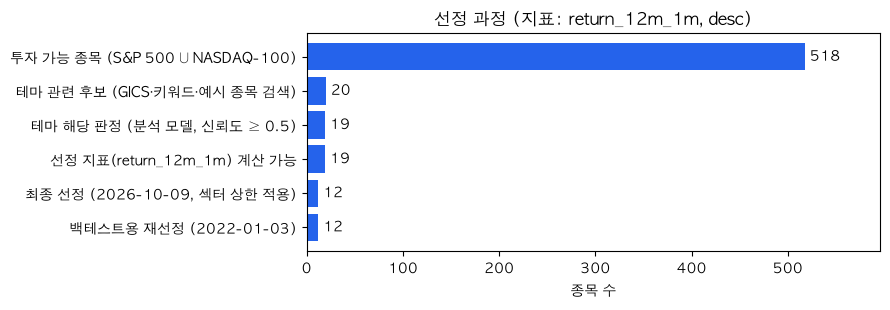

,회사,섹터,테마,신뢰도,순위(2022-01-03),지표(백테스트),순위(2026-10-09),지표(2026),테마 판정 사유
티커,,,,,,,,,
DPZ,Domino's,Consumer Discretionary,restaurant_franchises,0.95,1.0,+39.25%,NaN,+nan%,도미노스 피자 매장과 프랜차이즈 네트워크를 운영
HLT,Hilton Worldwide,Consumer Discretionary,hotels_resorts_cruises,0.85,2.0,+29.90%,8.0,+17.99%,호텔과 리조트를 관리·프랜차이즈하며 숙박 서비스를 제공
DRI,Darden Restaurants,Consumer Discretionary,restaurant_franchises,0.95,3.0,+26.00%,9.0,+13.96%,여러 브랜드의 풀서비스 레스토랑을 직접 운영
EXPE,Expedia Group,Consumer Discretionary,hotels_resorts_cruises,0.55,4.0,+22.77%,4.0,+31.32%,여행 예약 플랫폼에서 호텔·숙박 예약 서비스를 중개
CMG,Chipotle Mexican Grill,Consumer Discretionary,restaurant_franchises,0.95,5.0,+22.18%,NaN,+nan%,치폴레 브랜드의 멕시칸 레스토랑을 직접 운영
YUM,Yum! Brands,Consumer Discretionary,restaurant_franchises,0.95,6.0,+21.57%,12.0,+0.45%,KFC·타코벨 등 퀵서비스 레스토랑을 운영·프랜차이즈
HST,Host Hotels & Resorts,Real Estate,hotels_resorts_cruises,0.65,7.0,+11.58%,1.0,+45.68%,호텔·리조트 부동산을 보유해 숙박 사업을 지원
LUV,Southwest Airlines,Industrials,passenger_airlines,0.95,8.0,+0.68%,7.0,+21.36%,국내 여객 항공 노선을 운영하는 항공사
UAL,United Airlines Holdings,Industrials,passenger_airlines,0.95,9.0,+0.02%,10.0,+8.56%,미주와 국제 여객 항공 노선을 운영하는 항공사


백테스트 재선정에서 추가: ['CMG', 'DPZ'] | 빠짐: ['ABNB', 'SBUX']


,회사,제외 이유,지표값
티커,,,
CMG,Chipotle Mexican Grill,rank_beyond_n,-0.118350
MCD,McDonald's,rank_beyond_n,-0.118354
BKNG,Booking Holdings,rank_beyond_n,-0.144943
RCL,Royal Caribbean Group,rank_beyond_n,-0.148151
CCL,Carnival Corporation,rank_beyond_n,-0.210471
DPZ,Domino's,rank_beyond_n,-0.220858
NCLH,Norwegian Cruise Line Holdings,rank_beyond_n,-0.384713


In [4]:
S = R["selection"]
f = pd.DataFrame(S["funnel"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(f["label_ko"][::-1], f["count"][::-1], color="#2563eb")
for i, v in enumerate(f["count"][::-1]): ax.text(v + 5, i, str(v), va="center")
ax.set_xlabel("종목 수"); ax.set_title(f"선정 과정 (지표: {S['metric']}, {S['direction']})"); ax.set_xlim(0, f["count"].max() * 1.15)
plt.tight_layout(); plt.show()

t = pd.DataFrame(S["table"])
view = t[["ticker", "name", "sector", "themes", "theme_confidence", "rank_backtest", "metric_backtest", "rank_2026", "metric_2026", "theme_reason_ko"]].copy()
view["themes"] = view["themes"].str.join(", "); view["metric_backtest"] = view["metric_backtest"].map(pct); view["metric_2026"] = view["metric_2026"].map(pct)
view.columns = ["티커", "회사", "섹터", "테마", "신뢰도", f"순위({S['backtest_as_of']['as_of']})", "지표(백테스트)", f"순위({S['as_of_2026']['as_of']})", "지표(2026)", "테마 판정 사유"]
display(view.set_index("티커"))
diff = S["backtest_as_of"]["diff_vs_original"]
print("백테스트 재선정에서 추가:", diff["added"], "| 빠짐:", diff["removed"])
display(pd.DataFrame(S["as_of_2026"]["rejected_examples"]).rename(columns={"ticker": "티커", "name": "회사", "reason": "제외 이유", "metric_value": "지표값"}).set_index("티커"))

## 4. 포트폴리오 구성 — 기준 비중, 규칙 4가지, 시나리오 5개

기준은 1/N 동일비중이고, 종목·섹터 상한으로 재배분합니다. Black-Litterman 타겟은 기준 비중에 시나리오 뷰를 종목당 최대 `max_tilt` 만큼만 반영한 것입니다.

,섹터,1/N,최종 비중
DPZ,Consumer Discretionary,8.3%,8.5%
HLT,Consumer Discretionary,8.3%,6.9%
DRI,Consumer Discretionary,8.3%,5.4%
EXPE,Consumer Discretionary,8.3%,5.5%
CMG,Consumer Discretionary,8.3%,7.8%
YUM,Consumer Discretionary,8.3%,9.6%
HST,Real Estate,8.3%,10.4%
LUV,Industrials,8.3%,10.8%
UAL,Industrials,8.3%,7.0%
DAL,Industrials,8.3%,8.7%


적용된 제약: ['sector_cap:Consumer Discretionary'] | 섹터 비중: {'Consumer Discretionary': 0.5, 'Real Estate': 0.104, 'Industrials': 0.265, 'Communication Services': 0.131}


,설명,예상 변동성,유효 종목 수,최대 비중
규칙,,,,
동일비중,모든 종목에 같은 비중 1/N,34.1%,11.7,10.0%
시가총액비중,시가총액에 비례한 비중 (지수 방식),33.0%,10.4,15.0%
역변동성비중,변동성이 낮은 종목에 더 큰 비중 (1/σ 정규화),31.8%,11.2,13.1%
최소분산,포트폴리오 분산을 최소화하는 비중 (제약 포함 최적화),26.2%,7.3,15.0%


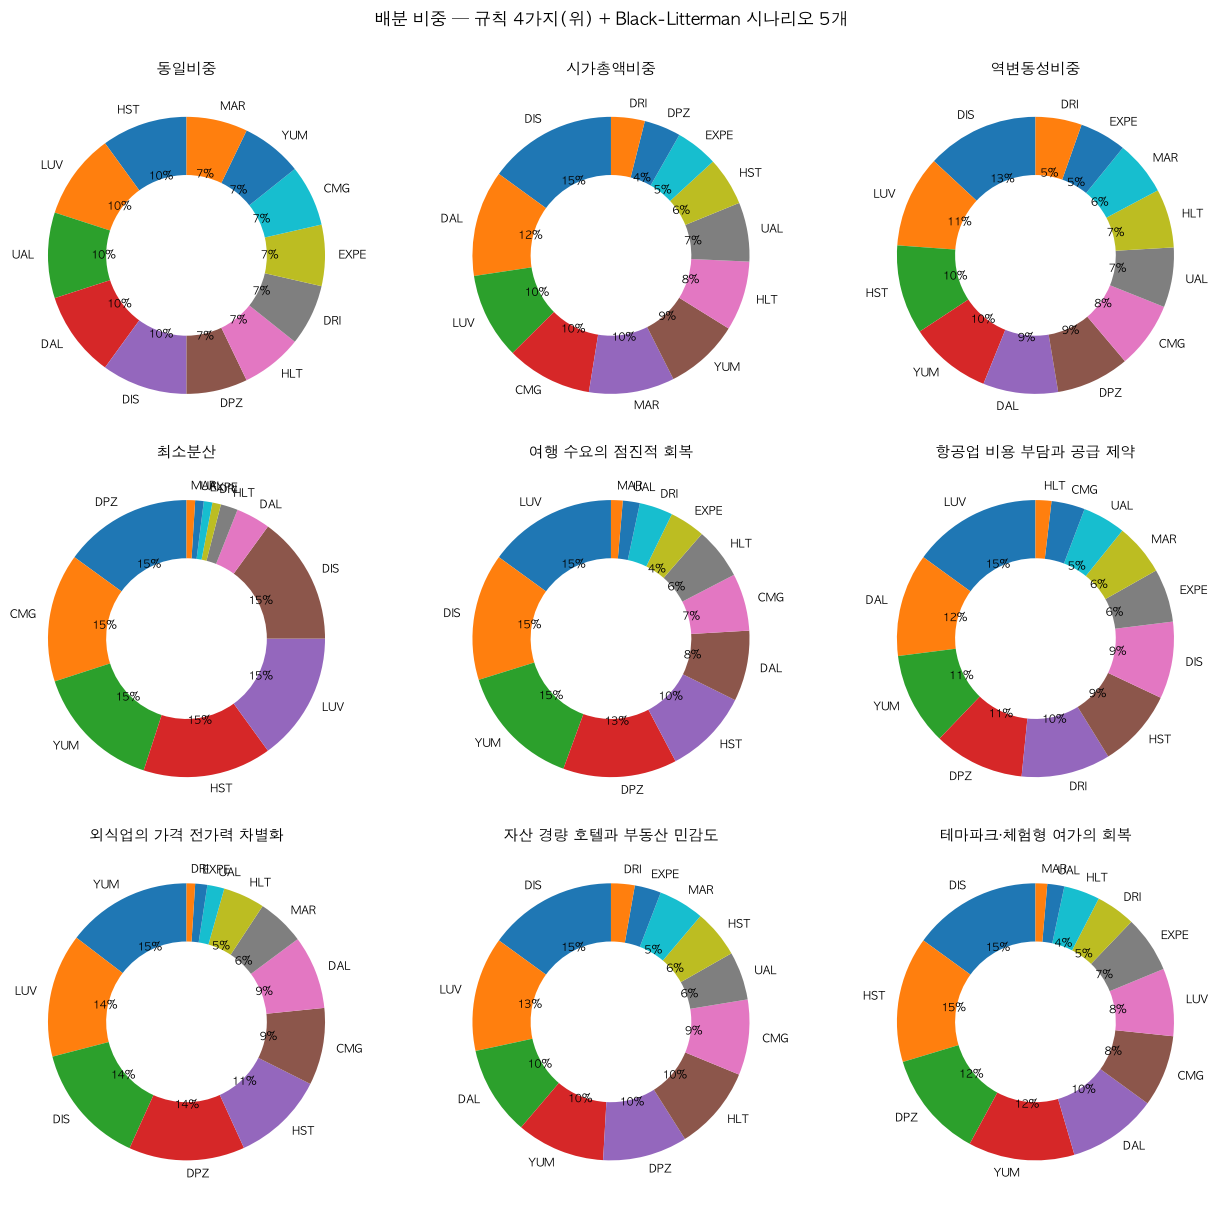

In [5]:
P = R["portfolio"]; base = next(p for p in P["baselines"]["portfolios"] if p["id"] == P["baselines"]["chosen_baseline"])
n = len(base["weights"]); sec = {x["ticker"]: x["sector"] for x in S["table"]}
bt_ = pd.DataFrame({"섹터": {t: sec.get(t, "") for t in base["weights"]}, "1/N": {t: 1/n for t in base["weights"]}, "최종 비중": base["weights"]})
display(bt_.style.format({"1/N": "{:.1%}", "최종 비중": "{:.1%}"}))
print("적용된 제약:", base["constraints_applied"], "| 섹터 비중:", {k: round(v, 3) for k, v in base["sector_weights"].items()})

tmpl = pd.DataFrame([{"규칙": p["name_ko"], "설명": p["rule_ko"], "예상 변동성": p["ex_ante"]["vol"], "유효 종목 수": p["ex_ante"]["effective_n"], "최대 비중": max(p["weights"].values())} for p in P["baselines"]["portfolios"]])
display(tmpl.set_index("규칙").style.format({"예상 변동성": "{:.1%}", "최대 비중": "{:.1%}", "유효 종목 수": "{:.1f}"}))

ports = P["baselines"]["portfolios"] + P["targets"]["portfolios"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, p in zip(axes.flat, ports):
    items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
    ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
    ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=11)
plt.suptitle("배분 비중 — 규칙 4가지(위) + Black-Litterman 시나리오 5개", y=1.0); plt.tight_layout(); plt.show()

,관점,뷰,최대 변화,예상 수익,예상 변동성
시나리오,,,,,
여행 수요의 점진적 회복,"오미크론 변이로 회복 시점은 불확실하지만, 백신 접종과 억눌린 여행 수요가 12개월 동안 숙박·항공 실적을 뒷받침할 수 있습니다. 포트폴리오에서는 호텔과 항공의 회복 여지를 반영하되, 종목별 변동성 때문에 확신은 중간 수준으로 둡니다.",[절대] HLT +45%/년 (신뢰 0.36) / [절대] DAL +50%/년 (신뢰 0.32) / [상대] HLT+MAR > DPZ+YUM +9%/년 (신뢰 0.35) / [상대] DAL+LUV > UAL +7%/년 (신뢰 0.28),+5.0%,32.5%,28.9%
항공업 비용 부담과 공급 제약,"연료비와 인건비 상승, 운항 인력·기재 제약이 항공 수요 회복의 수익성 전환을 늦출 수 있습니다. 항공사 전망은 긍정적으로 보되 기대수익을 보수적으로 잡고, 비용 부담이 큰 항공사보다 외식 프랜차이즈 쪽을 상대적으로 선호합니다.",[절대] LUV +100%/년 (신뢰 0.29) / [절대] UAL +100%/년 (신뢰 0.22) / [절대] DAL +100%/년 (신뢰 0.27) / [상대] DPZ+YUM > UAL+DAL +11%/년 (신뢰 0.34),+5.0%,48.5%,32.9%
외식업의 가격 전가력 차별화,"식재료와 임금 비용 상승은 외식업 전반의 마진을 압박하지만, 브랜드 인지도와 가격 조정 능력에 따라 영향은 달라질 수 있습니다. 프랜차이즈 비중이 높은 기업과 수요 충성도가 높은 브랜드에 무게를 두고, 풀서비스 레스토랑 대비 상대 우위를 가정합니다.",[절대] DPZ +13%/년 (신뢰 0.34) / [절대] YUM +22%/년 (신뢰 0.32) / [상대] YUM+DPZ > DRI+CMG +8%/년 (신뢰 0.30) / [상대] CMG > DRI +6%/년 (신뢰 0.25),+5.0%,29.0%,28.4%
자산 경량 호텔과 부동산 민감도,"여행 회복으로 객실 매출이 늘면 호텔 운영·프랜차이즈 기업의 수수료 수익과 레버리지 효과가 개선될 수 있습니다. 반면 호텔 부동산 보유 기업은 금리와 자본집약도에 더 민감할 수 있어, 포트폴리오에서는 자산 경량 호텔·여행 플랫폼을 상대적으로 선호합니다.",[절대] MAR +40%/년 (신뢰 0.30) / [절대] HST +34%/년 (신뢰 0.23) / [상대] MAR+HLT > HST +9%/년 (신뢰 0.32) / [상대] EXPE > HST +7%/년 (신뢰 0.25),+4.8%,36.1%,31.0%
테마파크·체험형 여가의 회복,"방문객 제한이 완화되고 소비자가 체험형 여가로 돌아오면 테마파크와 여행 예약 수요가 개선될 수 있습니다. 다만 디즈니는 스트리밍 투자와 사업부별 실적 차이가 변수이므로, 체험형 사업 회복에 대한 기대를 반영하면서도 강한 확신은 피합니다.",[절대] DIS +38%/년 (신뢰 0.30) / [절대] EXPE +43%/년 (신뢰 0.26) / [상대] DIS+MAR > DPZ+YUM +10%/년 (신뢰 0.28) / [상대] EXPE+DIS > LUV+UAL +8%/년 (신뢰 0.24),+5.0%,34.3%,29.8%


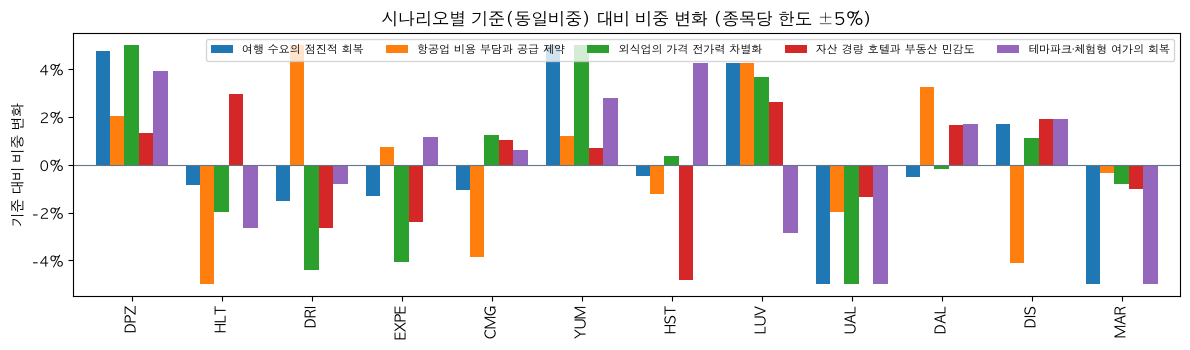

In [6]:
sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                    "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in P["targets"]["portfolios"]])
display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
dl = pd.DataFrame({p["title_ko"]: p["delta_vs_baseline"] for p in P["targets"]["portfolios"]})
ax = dl.plot.bar(figsize=(12, 3.6), width=0.8); ax.axhline(0, color="#64748b", lw=0.8); ax.set_ylabel("기준 대비 비중 변화"); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title(f"시나리오별 기준(동일비중) 대비 비중 변화 (종목당 한도 ±{P['targets']['parameters']['max_tilt_per_stock']:.0%})"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 5. 백테스트 — 같은 기간·같은 적립으로 9개 포트폴리오와 비교지수를 돌린 결과

In [7]:
BT = R["backtest"]; rec = R["validation"].get("recommended"); chosen = rec["id"] if rec else P["targets"]["baseline"]["id"]
label = lambda p: (f"시나리오: {p['title_ko']}" if p.get("title_ko") else p["name_ko"])
E = BT["engine"]; print(f"기간 {BT['period']['start']}~{BT['period']['end']} ({BT['period']['trading_days']}거래일) · 적립 {E['n_contributions']}회 × {E['contribution_usd']:.0f} USD · 거래비용 {E['commission_bps']}bp · 무위험 {E['risk_free_rate']:.0%} · {E['prices']}")
print("중심 포트폴리오:", chosen, "(추천)" if rec else "(추천 없음 → 기준 포트폴리오)")
rows = []
for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]:
    h, m = p["headline"], p["metrics"]
    rows.append({"포트폴리오": label(p), "종류": p["kind"], "누적수익": m["return"]["total_return"], "CAGR": h["cagr"], "변동성": m["risk"]["ann_vol"], "Sharpe": h["sharpe"], "최대낙폭": h["max_drawdown"],
                 "SPY 대비": h["excess_cagr"], "최종 평가금액": h["final_value_usd"], "투입 원금": p["money"]["net_invested_usd"], "XIRR": p["money"]["irr_annual"], "뷰 적중": h["view_hit_ratio"]})
comp = pd.DataFrame(rows).set_index("포트폴리오")
display(comp.style.format({"누적수익": "{:+.1%}", "CAGR": "{:+.1%}", "변동성": "{:.1%}", "Sharpe": "{:.2f}", "최대낙폭": "{:.1%}", "SPY 대비": "{:+.1%}", "최종 평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "XIRR": "{:+.1%}", "뷰 적중": "{:.0%}"}, na_rep="–").background_gradient(subset=["Sharpe"], cmap="Blues"))

기간 2022-01-03~2026-10-09 (1197거래일) · 적립 56회 × 421 USD · 거래비용 5bp · 무위험 4% · adj_close (dividends reinvested)
중심 포트폴리오: equal_weight (추천)


,종류,누적수익,CAGR,변동성,Sharpe,최대낙폭,SPY 대비,최종 평가금액,투입 원금,XIRR,뷰 적중
포트폴리오,,,,,,,,,,,
시나리오: 여행 수요의 점진적 회복,black_litterman,+26.4%,+5.1%,21.7%,0.05,-27.9%,-7.1%,"62,586","48,830",+7.0%,50%
시나리오: 항공업 비용 부담과 공급 제약,black_litterman,+44.3%,+8.0%,23.2%,0.17,-28.3%,-4.1%,"69,598","48,830",+10.1%,0%
시나리오: 외식업의 가격 전가력 차별화,black_litterman,+26.9%,+5.1%,21.6%,0.05,-26.7%,-7.0%,"62,283","48,830",+6.9%,25%
시나리오: 자산 경량 호텔과 부동산 민감도,black_litterman,+38.8%,+7.2%,23.0%,0.14,-27.8%,-5.0%,"67,181","48,830",+9.0%,50%
시나리오: 테마파크·체험형 여가의 회복,black_litterman,+32.4%,+6.1%,21.9%,0.10,-27.3%,-6.1%,"64,817","48,830",+8.0%,25%
동일비중,template,+57.3%,+10.0%,24.3%,0.25,-28.7%,-2.1%,"74,348","48,830",+12.0%,–
시가총액비중,template,+52.0%,+9.2%,23.9%,0.22,-28.2%,-2.9%,"72,177","48,830",+11.1%,–
역변동성비중,template,+45.6%,+8.2%,23.1%,0.18,-27.7%,-3.9%,"69,820","48,830",+10.1%,–
최소분산,template,+15.4%,+3.1%,21.1%,-0.04,-25.8%,-9.1%,"57,294","48,830",+4.5%,–


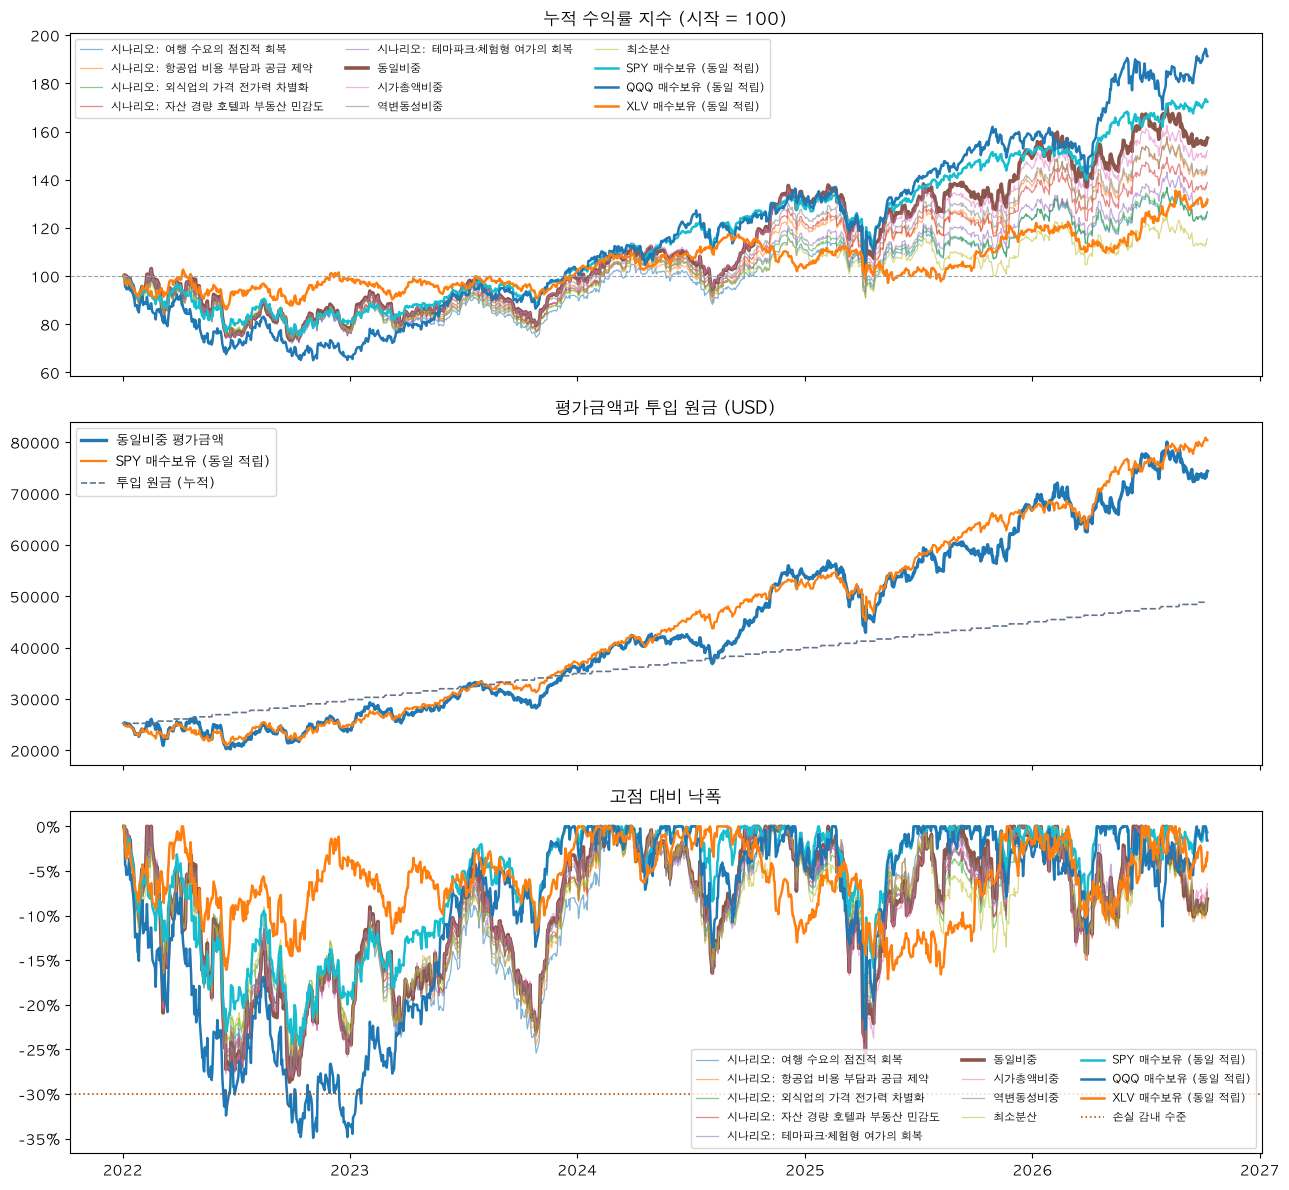

동일비중 최대낙폭 -28.7%: 고점 2022-02-16 → 저점 2022-09-26 → 회복 2024-02-07 (고점 아래 721일)


In [8]:
dates = pd.to_datetime(BT["series_dates"]); series = {p["id"]: p for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]}
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for pid, p in series.items():
    lw = 2.6 if pid == chosen else (1.8 if p["kind"] == "benchmark" else 0.9); alpha = 1 if (pid == chosen or p["kind"] == "benchmark") else 0.55
    axes[0].plot(dates, p["series"]["index"], lw=lw, alpha=alpha, label=label(p))
    axes[2].plot(dates, p["series"]["drawdown"], lw=lw, alpha=alpha, label=label(p))
axes[0].axhline(100, color="#94a3b8", ls="--", lw=0.8); axes[0].set_title("누적 수익률 지수 (시작 = 100)"); axes[0].legend(ncol=3, fontsize=8)
cp = series[chosen]; led = {l["date"]: l["amount_usd"] for l in cp["contribution_ledger"]}; inv, cum = [], cp["money"]["initial_usd"]
for ds in BT["series_dates"]: cum += led.get(ds, 0.0); inv.append(cum)
axes[1].plot(dates, cp["series"]["value_usd"], lw=2.4, label=f"{label(cp)} 평가금액"); axes[1].plot(dates, series[BT["benchmark"]["id"]]["series"]["value_usd"], lw=1.6, label="SPY 매수보유 (동일 적립)")
axes[1].plot(dates, inv, lw=1.2, ls="--", color="#64748b", label="투입 원금 (누적)"); axes[1].set_title("평가금액과 투입 원금 (USD)"); axes[1].legend(fontsize=9)
axes[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); axes[2].set_title("고점 대비 낙폭"); axes[2].axhline(-R["intent"]["risk_params"]["effective_max_drawdown"], color="#b45309", ls=":", lw=1.2, label="손실 감내 수준")
axes[2].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()
mdd = cp["metrics"]["risk"]["mdd"]; print(f"{label(cp)} 최대낙폭 {cp['headline']['max_drawdown']:.1%}: 고점 {mdd['peak_date']} → 저점 {mdd['trough_date']} → 회복 {mdd['recovery_date'] or '기간 내 미회복'} (고점 아래 {mdd['underwater_days']}일)")

,2022,2023,2024,2025,2026
동일비중,-21.6%,+26.6%,+33.0%,+12.8%,+5.6%
SPY 매수보유 (동일 적립),-18.7%,+26.2%,+24.9%,+17.7%,+14.4%
역변동성비중,-22.1%,+24.6%,+28.7%,+11.3%,+4.8%


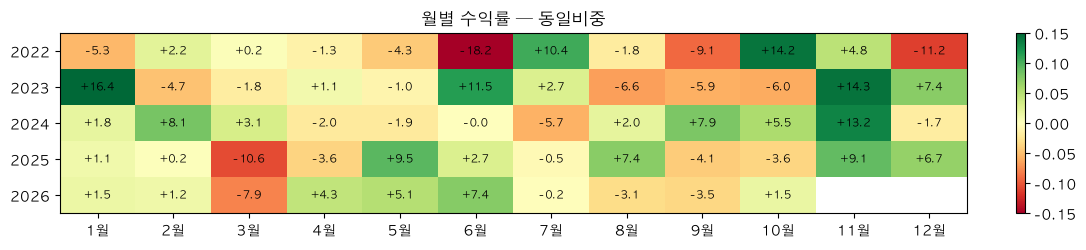

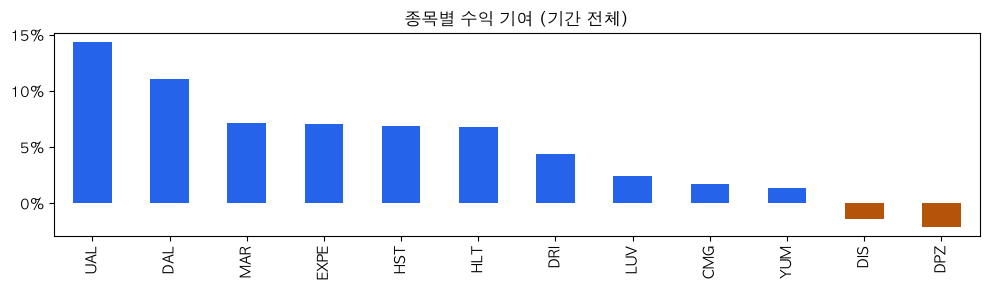

In [9]:
yr = pd.DataFrame({label(p): p["yearly_returns"] for p in [cp, series[BT["benchmark"]["id"]], series[P["targets"]["baseline"]["id"]]]}).T
display(yr.style.format("{:+.1%}", na_rep="–").set_caption("연도별 수익률 (첫해·마지막 해는 부분 기간)"))
mr = pd.DataFrame(cp["monthly_returns"]).pivot(index="year", columns="month", values="return")
fig, ax = plt.subplots(figsize=(11, 2.6)); im = ax.imshow(mr.values, cmap="RdYlGn", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([f"{m}월" for m in range(1, 13)]); ax.set_yticks(range(len(mr.index))); ax.set_yticklabels(mr.index)
for i in range(mr.shape[0]):
    for j in range(mr.shape[1]):
        v = mr.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"월별 수익률 — {label(cp)}"); plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()
contrib = pd.Series(cp["ticker_contribution"]).sort_values(ascending=False)
ax = contrib.plot.bar(figsize=(10, 3), color=["#2563eb" if v >= 0 else "#b45309" for v in contrib]); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_title("종목별 수익 기여 (기간 전체)"); plt.tight_layout(); plt.show()

### 리밸런싱 시점별 구성과 성과
각 리밸런싱일의 **조정 후 비중**(행)과 그 **직전 구간 성과**, 그 시점까지의 누적 지표입니다.

In [10]:
cps = cp["checkpoints"]
wt = pd.DataFrame({c["date"]: c["weights"]["after"] for c in cps}).T
display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption(f"리밸런싱 후 비중 — {label(cp)}"))
rows = []
for c in cps:
    sl, td = c["since_last"] or {}, c["to_date"] or {}
    rows.append({"날짜": c["date"], "구분": c["kind"], "평가금액": c["money"]["value_usd"], "투입 원금": c["money"]["net_invested_usd"], "구간 수익": sl.get("return"), "SPY 구간": sl.get("benchmark_return"),
                 "구간 최대낙폭": sl.get("max_drawdown"), "최고 종목": f"{sl['best']['ticker']} {sl['best']['return']:+.1%}" if sl else "", "최저 종목": f"{sl['worst']['ticker']} {sl['worst']['return']:+.1%}" if sl else "",
                 "누적 CAGR": td.get("cagr"), "누적 MDD": td.get("max_drawdown"), "누적 Sharpe": td.get("sharpe"), "거래": len(c["trades"]), "비용": c["commission_usd"]})
display(pd.DataFrame(rows).set_index("날짜").style.format({"평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "구간 수익": "{:+.1%}", "SPY 구간": "{:+.1%}", "구간 최대낙폭": "{:.1%}", "누적 CAGR": "{:+.1%}", "누적 MDD": "{:.1%}", "누적 Sharpe": "{:.2f}", "비용": "{:.2f}"}, na_rep="–"))

,DPZ,HLT,DRI,EXPE,CMG,YUM,HST,LUV,UAL,DAL,DIS,MAR
2022-01-03,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2022-07-01,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2023-01-03,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2023-07-03,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2024-01-02,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2024-07-01,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2025-01-02,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2025-07-01,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2026-01-02,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%
2026-07-01,7.1%,7.1%,7.1%,7.1%,7.1%,7.1%,10.0%,10.0%,10.0%,10.0%,10.0%,7.1%


,구분,평가금액,투입 원금,구간 수익,SPY 구간,구간 최대낙폭,최고 종목,최저 종목,누적 CAGR,누적 MDD,누적 Sharpe,거래,비용
날짜,,,,,,,,,,,,,
2022-01-03,rebalance,"25,245","25,257",–,–,–,,,–,–,–,12,12.62
2022-07-01,rebalance,"21,049","27,362",-23.7%,-19.7%,-27.4%,HST -10.6%,EXPE -47.9%,-42.3%,-27.4%,-1.26,12,1.03
2023-01-03,rebalance,"23,924","29,888",+2.1%,+0.7%,-18.1%,DRI +24.8%,DPZ -15.4%,-22.2%,-28.7%,-0.80,12,0.96
2023-07-03,rebalance,"32,340","32,413",+23.4%,+17.4%,-14.8%,CMG +54.9%,DPZ +0.0%,-2.6%,-28.7%,-0.23,12,1.89
2024-01-02,rebalance,"35,919","34,939",+2.6%,+7.3%,-19.5%,EXPE +31.9%,UAL -26.0%,-0.7%,-28.7%,-0.18,12,2.72
2024-07-01,rebalance,"41,324","37,465",+8.1%,+16.1%,-5.9%,CMG +37.7%,EXPE -17.7%,+2.6%,-28.7%,-0.06,12,2.18
2025-01-02,rebalance,"53,593","39,990",+22.7%,+7.9%,-13.0%,UAL +97.5%,DPZ -13.3%,+9.4%,-28.7%,0.23,12,4.38
2025-07-01,rebalance,"56,539","42,516",+0.5%,+6.3%,-25.6%,DRI +19.5%,DAL -16.6%,+8.2%,-28.7%,0.17,12,2.53
2026-01-02,rebalance,"67,137","45,042",+13.9%,+11.2%,-8.6%,EXPE +63.2%,CMG -35.6%,+10.7%,-28.7%,0.27,12,6.05


In [11]:
vd = [(label(p), v["type"], v["summary_ko"].split(" — ")[0], v["expected_return_annual"], v["realized"], "적중" if v["hit"] else "빗나감") for p in BT["portfolios"] for v in p["view_diagnostics"]]
if vd:
    display(pd.DataFrame(vd, columns=["시나리오", "유형", "뷰", "기대", "실제(12개월)", "방향"]).style.format({"기대": "{:+.0%}", "실제(12개월)": "{:+.1%}"}).set_caption("시나리오 뷰 사후 점검 (구성 후 12개월 실현 수익)"))

,시나리오,유형,뷰,기대,실제(12개월),방향
0,시나리오: 여행 수요의 점진적 회복,absolute,[절대] HLT +45%/년 (신뢰 0.36),+45%,-18.8%,빗나감
1,시나리오: 여행 수요의 점진적 회복,absolute,[절대] DAL +50%/년 (신뢰 0.32),+50%,-19.1%,적중
2,시나리오: 여행 수요의 점진적 회복,relative,[상대] HLT+MAR > DPZ+YUM +9%/년 (신뢰 0.35),+9%,+7.5%,적중
3,시나리오: 여행 수요의 점진적 회복,relative,[상대] DAL+LUV > UAL +7%/년 (신뢰 0.28),+7%,-4.3%,빗나감
4,시나리오: 항공업 비용 부담과 공급 제약,absolute,[절대] LUV +100%/년 (신뢰 0.29),+100%,-25.9%,빗나감
5,시나리오: 항공업 비용 부담과 공급 제약,absolute,[절대] UAL +100%/년 (신뢰 0.22),+100%,-18.2%,빗나감
6,시나리오: 항공업 비용 부담과 공급 제약,absolute,[절대] DAL +100%/년 (신뢰 0.27),+100%,-19.1%,빗나감
7,시나리오: 항공업 비용 부담과 공급 제약,relative,[상대] DPZ+YUM > UAL+DAL +11%/년 (신뢰 0.34),+11%,-3.0%,빗나감
8,시나리오: 외식업의 가격 전가력 차별화,absolute,[절대] DPZ +13%/년 (신뢰 0.34),+13%,-37.9%,빗나감
9,시나리오: 외식업의 가격 전가력 차별화,absolute,[절대] YUM +22%/년 (신뢰 0.32),+22%,-5.2%,적중


## 6. 검증 — 사용자 기준(손실 감내 수준·목표 수익·제약)에 비춰 본 판정

In [12]:
V = R["validation"]; print("기준:", {k: V["criteria"][k] for k in ["max_drawdown", "target_annual_return", "benchmark", "volatility_preference", "max_weight_per_stock", "max_weight_per_sector", "min_holdings"]})
mat = pd.DataFrame({label(series[r["id"]]): {c["rule"] + " " + c["name_ko"]: c["status"] for c in r["checks"]} for r in V["results"]}).T
color = lambda s: "background-color:#dcfce7" if s == "pass" else ("background-color:#fef3c7" if s == "warn" else "background-color:#fee2e2")
display(mat.style.map(color).set_caption("규칙별 판정 (pass 통과 / warn 주의 / fail 미통과)"))
print("요약:", V["summary"]); print("추천:", V["recommended"]["id"] + " — " + V["recommended"]["reason_ko"] if V["recommended"] else "추천 없음 — " + "; ".join(V["warnings"]))
for alt in V.get("alternatives", []): print(f"대안 {alt['name_ko']}: {alt['reason_ko']} 판정 {alt['status']}")
inf = V["criteria"].get("selection_infeasibility")
if inf: print(f"종목 수 미달 사유: 섹터 상한 {inf['sector_cap']:.0%} 로 최대 {inf['max_feasible_n']}종목 (목표 {inf['target']}); 선택지: " + " / ".join(inf["options_ko"]))
chk = pd.DataFrame(next(r for r in V["results"] if r["id"] == chosen)["checks"])[["rule", "name_ko", "level", "status", "message_ko"]]
display(chk.set_index("rule").rename(columns={"name_ko": "항목", "level": "수준", "status": "판정", "message_ko": "측정 결과"}).style.set_caption(f"{label(cp)} 상세"))

기준: {'max_drawdown': 0.3, 'target_annual_return': 0.1, 'benchmark': 'SPY', 'volatility_preference': 'medium', 'max_weight_per_stock': 0.15, 'max_weight_per_sector': 0.5, 'min_holdings': 10}


,R1 최대낙폭,R2 목표수익,R3 비교지수 대비,R4 종목 상한(리밸런싱일),R4b 종목 상한(드리프트),R5 섹터 상한(리밸런싱일),R5b 섹터 상한(드리프트),R6 종목 수,R7 변동성 적합,R8 데이터 무결성
시나리오: 여행 수요의 점진적 회복,pass,warn,warn,pass,warn,pass,pass,pass,pass,pass
시나리오: 항공업 비용 부담과 공급 제약,pass,warn,warn,pass,pass,pass,pass,pass,pass,pass
시나리오: 외식업의 가격 전가력 차별화,pass,warn,warn,pass,warn,pass,pass,pass,pass,pass
시나리오: 자산 경량 호텔과 부동산 민감도,pass,warn,warn,pass,pass,pass,pass,pass,pass,pass
시나리오: 테마파크·체험형 여가의 회복,pass,warn,warn,pass,warn,pass,pass,pass,pass,pass
동일비중,pass,pass,warn,pass,pass,pass,pass,pass,pass,pass
시가총액비중,pass,warn,warn,pass,pass,pass,pass,pass,pass,pass
역변동성비중,pass,warn,warn,pass,pass,pass,pass,pass,pass,pass
최소분산,pass,warn,warn,pass,warn,pass,pass,pass,pass,pass


요약: {'n_pass': 0, 'n_warn': 9, 'n_fail': 0}
추천: equal_weight — 검증 실패 없는 포트폴리오 중 Sharpe 최고(0.25). CAGR 10.0%, 최대낙폭 -28.7%, 최종 평가금액 74,348 USD.


,항목,수준,판정,측정 결과
rule,,,,
R1,최대낙폭,hard,pass,최대낙폭 28.7% ≤ 허용 30%
R2,목표수익,soft,pass,CAGR 10.0% vs 목표 10%
R3,비교지수 대비,soft,warn,SPY 대비 초과 CAGR -2.1%
R4,종목 상한(리밸런싱일),hard,pass,리밸런싱일 최대 종목 비중 10.0% vs 상한 15%
R4b,종목 상한(드리프트),soft,pass,리밸런싱 사이 종목 비중 드리프트 허용 범위 안
R5,섹터 상한(리밸런싱일),hard,pass,리밸런싱일 최대 섹터 비중 50.0% vs 상한 50%
R5b,섹터 상한(드리프트),soft,pass,리밸런싱 사이 섹터 드리프트 허용 범위 안
R6,종목 수,hard,pass,보유 종목 12개 vs 최소 10개
R7,변동성 적합,soft,pass,연변동성 24.3% vs 성향(medium) 상한 30%


## 6b. 뉴스가 바꾼 것 — walk-forward (리밸런싱마다 직전 2주 뉴스로 뷰를 새로 만든 결과)

In [13]:
WF = R["portfolio"].get("walkforward"); EVD = (R["portfolio"].get("news_evidence") or {}).get("all_evidence", {})
if not WF:
    print("walk-forward 결과 없음 (--news 로 실행한 경우에만 생성)")
else:
    bl = next(p for p in WF["portfolios"] if p["kind"] == "black_litterman"); base = next(p for p in WF["portfolios"] if p["id"] == "wf_equal_weight")
    rows = []
    for d in WF["dates"]:
        ns = WF["news_summary"][d]; views = bl["views_by_date"].get(d, []); w = bl["weights_by_date"][d]; b = base["weights_by_date"][d]
        top = sorted(((t, w[t] - b[t]) for t in w), key=lambda x: -abs(x[1]))[:3]
        rows.append({"리밸런싱일": d, "뉴스 창": f"{ns['window'][0]}~{ns['window'][1]}", "기사": ns["n_articles"], "뉴스 있는 종목": ns["n_tickers_with_news"],
                     "출처": ", ".join(f"{k} {v}" for k, v in ns["origin_counts"].items() if v), "뷰": len(views), "기준 대비 변화(상위 3)": ", ".join(f"{t} {x:+.1%}" for t, x in top) if views else "기준 비중 유지"})
    display(pd.DataFrame(rows).set_index("리밸런싱일"))
    vrows = [{"날짜": d, "뷰": v["summary_ko"].split(" — ")[0], "신뢰도": v["confidence"], "근거": ", ".join(v.get("evidence_ids", [])), "이유": v.get("rationale_ko", "")} for d in WF["dates"] for v in bl["views_by_date"].get(d, [])]
    if vrows: display(pd.DataFrame(vrows).set_index("날짜"))
    used = sorted({i for d in WF["dates"] for v in bl["views_by_date"].get(d, []) for i in v.get("evidence_ids", [])})
    if used:
        erows = [{"근거": i, "날짜": EVD[i]["published_at"], "종목": EVD[i]["ticker"], "출처": "팀 DB" if EVD[i].get("origin", "db") == "db" else "웹 검색", "발행사": EVD[i].get("publisher") or EVD[i].get("source"), "제목": EVD[i]["title"][:90], "url": EVD[i]["url"]} for i in used if i in EVD]
        display(pd.DataFrame(erows).set_index("근거"))
    wt = pd.DataFrame({d: bl["weights_by_date"][d] for d in WF["dates"]}).T
    display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption("뉴스 뷰 BL — 리밸런싱일별 타겟 비중"))
    for pid in [bl["id"], "wf_equal_weight"]:
        p = series.get(pid)
        if p: print(f"{p['name_ko']}: 기간 수익률 {p['headline']['period_return']:+.2%}, 최대낙폭 {p['headline']['max_drawdown']:.2%}, 최종 {p['headline']['final_value_usd']:,.0f} USD")

walk-forward 결과 없음 (--news 로 실행한 경우에만 생성)


## 6c. 지금 구성한다면 — 최신 가격·뉴스 기준 (백테스트 없음)

기준일 2026-10-09 · 뉴스 창 2026-09-25~2026-10-09 · 기사 120건 · 뉴스 있는 종목 12 · δ=7.5752 (market_implied)


,관점,뷰,근거 수,최대 변화,예상 수익,예상 변동성
시나리오,,,,,,
항공 노선 확대와 예약 접점,Southwest의 신규 직항 노선과 ChatGPT 내 항공편 예약 도입은 판매·예약 접점 확대의 신호로 해석했습니다. Delta는 국제선 프리미엄 전략과 텍사스 확장 목표가 보도됐지만 국내선 축소와 United의,[절대] LUV +50%/년 (신뢰 0.25) / [상대] LUV > UAL +10%/년 (신뢰 0.25) / [상대] DAL > UAL +6%/년 (신뢰 0.20),5,+5.0%,32.1%,21.0%
호텔 브랜드·지역 확장,Marriott의 코스타리카 올인클루시브 리조트 개장과 네덜란드 호텔 계약은 브랜드·지역 확장 흐름으로 해석했습니다. Host의 거래일 강세와 기술적 돌파 관련 보도도 있으나 고점 아래라는 보도와 Hilton의 보유,[절대] MAR +40%/년 (신뢰 0.30) / [절대] HST +34%/년 (신뢰 0.20) / [상대] MAR > HLT +8%/년 (신뢰 0.25) / [상대] HST > HLT +4%/년 (신뢰 0.20),5,+5.0%,36.0%,21.7%
여행 예약 플랫폼의 서비스와 규제 리스크,"Expedia의 라운지 접근 등 로열티 혜택 추가는 고객 서비스 강화로, Airbnb의 체험 상품 보도는 이용 선택지 확대로 해석했습니다. 다만 Airbnb에는 지역 내 영업 제한 제안과 법적 분쟁 보도가 있고 Ex",[절대] EXPE +48%/년 (신뢰 0.25) / [상대] EXPE > ABNB +10%/년 (신뢰 0.25) / [상대] EXPE > HLT +4%/년 (신뢰 0.20),6,+2.4%,33.4%,21.3%
외식업체의 실적·운영 신호,"Darden은 실적 상회 보도에도 주가 하락과 전망 하향 관련 보도가 있어 단기 기대를 보수적으로 봤습니다. Starbucks는 턴어라운드에 집중한다는 입장과 함께 소송·매장 폐쇄 보도가 나왔고, Yum에는 목표 하",[상대] DRI > SBUX +6%/년 (신뢰 0.25) / [상대] YUM > SBUX +5%/년 (신뢰 0.20),5,+5.0%,32.3%,21.0%
크루즈·레저 상품 확대,"Disney의 신규 크루즈선과 선내 공연·식사 콘텐츠 발표는 향후 여가 상품 확대의 근거로 해석했습니다. 다만 테마파크 연간 이용권 프로그램 검토 보도도 있어 수익성 개선으로 단정하지 않았으며, 여행·숙박 업체와의",[절대] DIS +36%/년 (신뢰 0.25) / [상대] DIS > ABNB +5%/년 (신뢰 0.20) / [상대] DIS > HLT +3%/년 (신뢰 0.15) / [상대] MAR > HST +4%/년 (신뢰 0.20),8,+2.5%,34.3%,21.4%


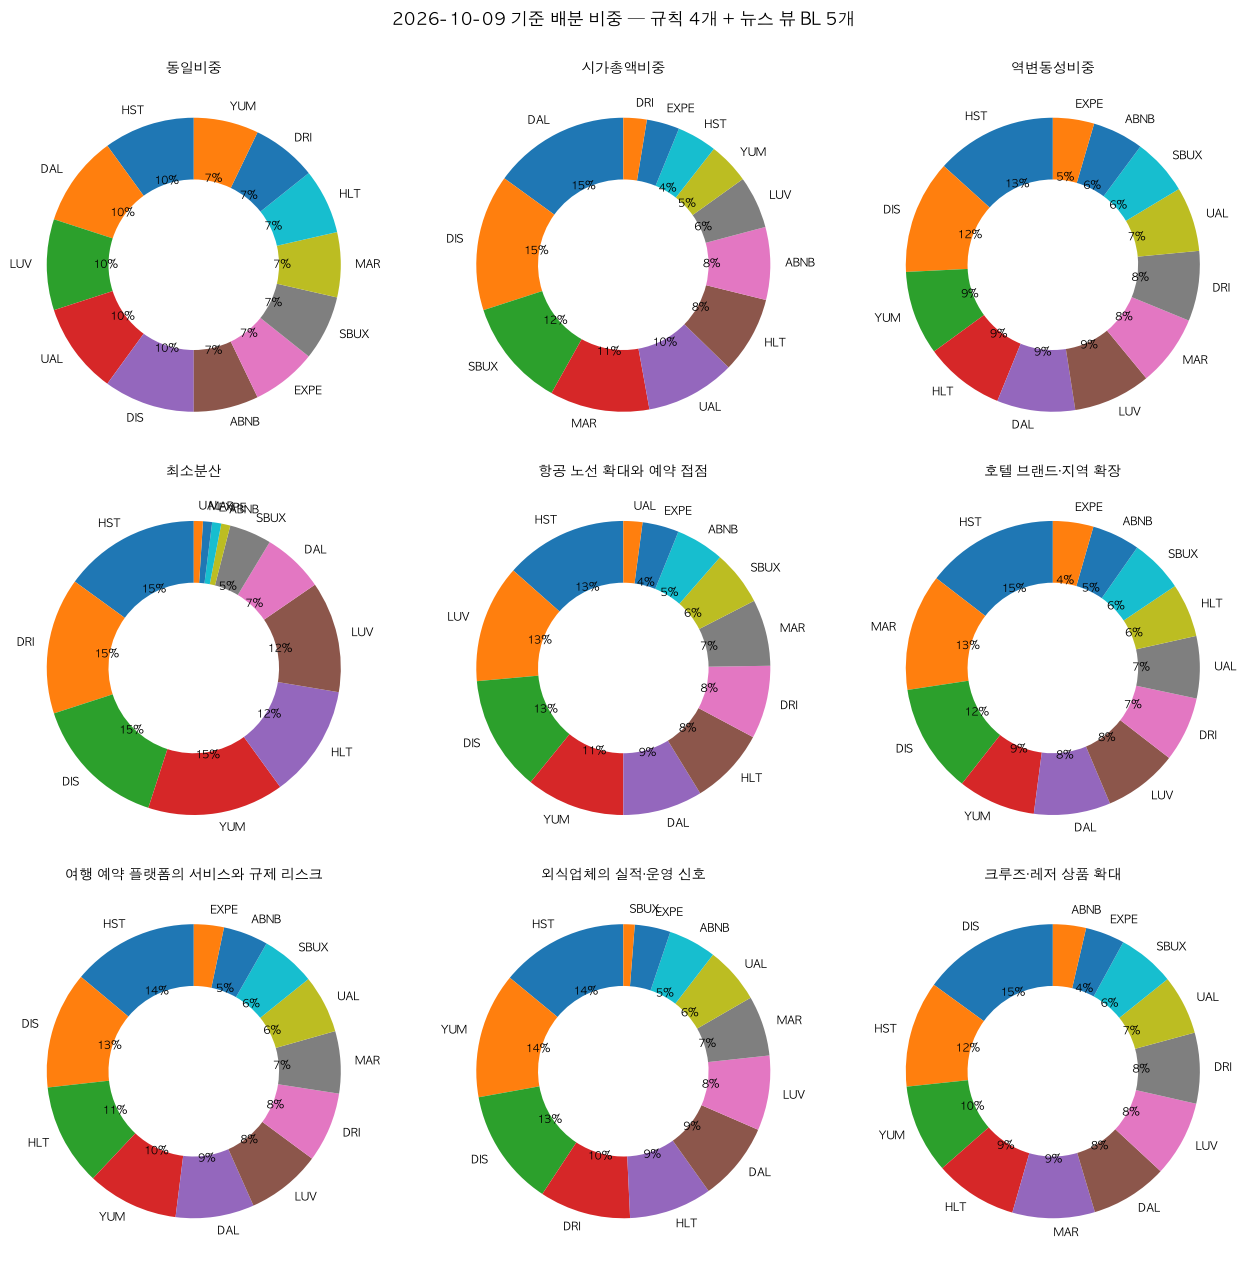

,비중,USD,원화
티커,,,
HST,13.5%,"3,013.61","4,038,301"
LUV,13.0%,"2,904.27","3,891,781"
DIS,12.7%,"2,845.82","3,813,451"
YUM,10.9%,"2,431.46","3,258,211"
DAL,8.8%,"1,960.67","2,627,341"
HLT,8.4%,"1,890.67","2,533,531"
DRI,8.0%,"1,798.18","2,409,601"
MAR,7.3%,"1,636.39","2,192,790"
SBUX,6.0%,"1,348.93","1,807,590"


In [14]:
F = R["portfolio"].get("forward")
if not F:
    print("현재 구성 결과 없음")
else:
    nw = F.get("news_window"); print(f"기준일 {F['as_of']} · 뉴스 창 {nw['window'][0]}~{nw['window'][1]} · 기사 {nw['n_articles']}건 · 뉴스 있는 종목 {nw['n_tickers_with_news']} · δ={F['market_model']['delta']} ({F['market_model']['delta_source']})" if nw else f"기준일 {F['as_of']}")
    sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0][:120], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                        "근거 수": len({i for v in p["views_applied"] for i in v.get("evidence_ids", [])}), "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in F["portfolios"]])
    display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
    ports = F["templates"] + F["portfolios"]
    cols = 3; rows_ = -(-len(ports) // cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(13, 4.2 * rows_))
    for ax, p in zip(axes.flat, ports):
        items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
        ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
        ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=10)
    for ax in list(axes.flat)[len(ports):]: ax.axis("off")
    plt.suptitle(f"{F['as_of']} 기준 배분 비중 — 규칙 4개 + 뉴스 뷰 BL {len(F['portfolios'])}개", y=1.0); plt.tight_layout(); plt.show()
    chosen = F["portfolios"][0] if F["portfolios"] else F["templates"][0]
    display(pd.DataFrame(chosen["allocation"]).rename(columns={"ticker": "티커", "weight": "비중", "usd": "USD", "krw": "원화"}).set_index("티커").style.format({"비중": "{:.1%}", "USD": "{:,.2f}", "원화": "{:,.0f}"}).set_caption(f"배분 금액 — {chosen['name_ko']} (투자금 {F['capital']['initial_amount_usd']:,.0f} USD)"))

## 7. 비용·조건·경고

In [15]:
u = R["llm_usage"]
if u.get("available"):
    display(pd.DataFrame(u["by_stage"]).T.style.format({"cost_usd": "{:.4f}"}).set_caption(f"분석 모델 호출 (누적, {u['model']}) — 합계 {u['total_cost_usd']:.4f} USD"))
display(pd.DataFrame(R["sources"])[["name", "what"]].rename(columns={"name": "출처", "what": "사용한 내용"}).set_index("출처"))
print("파라미터:", json.dumps(R["parameters"], ensure_ascii=False)[:600])
pd.DataFrame(R["warnings"]).rename(columns={"stage": "단계", "message": "경고"})

,calls,prompt_tokens,completion_tokens,cost_usd
02_intent,1.000000,6531.000000,2258.000000,0.0023
04_classify,1.000000,1507.000000,2213.000000,0.0014
09_views,1.000000,2049.000000,4412.000000,0.0027
09n_forward,1.000000,6949.000000,5394.000000,0.0043


,사용한 내용
출처,
팀 데이터베이스 price_daily,"일별 주가·수정주가·거래량 (여러 소스의 합의값 CONSENSUS 우선, 1종목·1일 1행)"
팀 데이터베이스 financials (SEC EDGAR),발행주식수 (시가총액 필터·시가총액 비중)
팀 데이터베이스 fx_daily,원/달러 환율 USDKRW (투자금 환산 기준일 종가)
Yahoo Finance (yfinance) 캐시 사본,비교지수 ETF (SPY·QQQ·XLV) — 팀 DB 미보유로 캐시 사본 사용
팀 데이터베이스 news,"종목 뉴스 헤드라인 (GOOGLE_RSS·NEWSAPI·NAVER_NEWS), 구성일 직전 14일 창"
Wikipedia,S&P 500 · NASDAQ-100 구성 종목과 GICS 세부산업
Wikipedia GICS,GICS 11 섹터 / 25 산업그룹 / 74 산업 / 163 세부산업 분류표
MyFinSight 파이프라인 계산,후보 검색·정량 스크린·비중 계산·Black-Litterman·백테스트(bt)·검증 규칙
분석 모델 (gpt-6-luna),"의도 해석, 테마 분류, 시나리오 뷰(정적 뷰는 뉴스 미연결, walk-forward·현재 구성은 DB 뉴스 근거), 리포트 서술"


파라미터: {"portfolio": {"LOOKBACK_DAYS": 756, "SHRINKAGE": "ledoit_wolf", "TAU": 0.05, "RISK_AVERSION": {"conservative": 4.0, "moderate": 2.5, "aggressive": 1.5}, "OMEGA_METHOD": "he_litterman_confidence", "CONFIDENCE_FLOOR": 0.1, "ABS_RETURN_RANGE": [-0.5, 1.0], "REL_RETURN_RANGE": [0.0, 0.5], "TEMPLATES": ["equal_weight", "market_cap", "inverse_volatility", "min_variance"]}, "backtest": {"COMMISSION_BPS": 5, "INTEGER_POSITIONS": false, "RISK_FREE_RATE": 0.04, "TRADING_DAYS": 252, "DRIFT_TOLERANCE": 0.25, "CHECKPOINT_FREQ": "rebalance", "VOL_BANDS": {"low": 0.15, "medium": 0.3, "high": 9.99}}, "llm": 


,단계,경고
0,02,theme passenger_airlines: dropped tickers outside universe ['AAL']
1,02,theme theme_parks_and_leisure: dropped tickers outside universe ['FUN']
2,05,sector name preference (6/sector) exceeded for 1 tickers ['YUM']; sector cap...
3,07,stage5@2022-01-03: sector name preference (6/sector) exceeded for 1 tickers ...
4,07,"capital re-converted at 2022-01-03 FX 1187.78: 25,257 USD vs request-date 22..."
5,09,"airline_cost_and_capacity: return 34.0 clipped to [-0.5, 1.0]"
6,09,"airline_cost_and_capacity: return 61.0 clipped to [-0.5, 1.0]"
7,09,"airline_cost_and_capacity: return 50.0 clipped to [-0.5, 1.0]"
8,12,alternative skipped: chosen portfolio already within the drawdown tolerance
9,10f,"airline_routes_and_booking: view dropped, malformed legs long=[] short=['UAL']"
